# Q1B | Display the Statistical Values

> Display the statistical values for each of the attributes, along with visualizations (ex: histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?

**IMPORTANT**
This notebook uses only the train dataset, so no analysis or treatment decision is influenced by the test data (data snooping).

# Answer Summary

**Statistics and visualizations**
- Each attribute has a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Life Ladder`) and five plots: histogram, QQ plot, box plot, a scatter against `Life Ladder` (linear, LOWESS and the best candidate shapes), and a chart of every candidate shape's R² gain over the linear fit. The target has the table, histogram and QQ plot.

**Noticeable traits**
- Target: roughly symmetric, with no missing values and no IQR outliers.
- Strength of the relationship with `Life Ladder`: strong for `Log GDP per capita`, `Healthy life expectancy at birth` and `Social support`. Moderate for `Positive affect`, `Freedom to make life choices` and `Perceptions of corruption`. Weak for `Negative affect` and `Generosity`.
- Shape: `Social support`, `Healthy life expectancy at birth` and `Freedom to make life choices` are shallow at the low end and steep at the top, so the straight line under-predicts both ends, and their best shape gains +0.0448 to +0.0679 in R². `Generosity` is a level shift, not a slope: a single 0 / 1 flag reaches LOWESS. `Log GDP per capita` and `Negative affect` bend only a little, and `Perceptions of corruption` and `Positive affect` are already straight (their best shape gains about 0.01).
- Outliers sit on the trend: the low tails of `Perceptions of corruption`, `Social support`, `Healthy life expectancy at birth` and `Freedom to make life choices`, and the high tail of `Negative affect`, follow LOWESS. Only the high tail of `Generosity` sits off the straight line.
- Scale: `Healthy life expectancy at birth` has a std of 7.478, while six of the other seven attributes are under 0.2.

**Special treatment**
- Feature engineering: recommend a hinge on `Social support` (t = 0.844) and `Freedom to make life choices` (t = 0.8), a floor at 56.8 or a hinge at 57.5 on `Healthy life expectancy at birth`, and a high generosity flag (1 when `Generosity` is at or above 0.087) in place of raw `Generosity`. Worth testing, small gain: a hinge on `Log GDP per capita` (t = 10.1) and `Negative affect` (t = 0.202). Avoid every shape on `Perceptions of corruption` (including a low corruption flag) and `Positive affect`, and a 0 / 1 flag (step) on every attribute except `Generosity`: it loses R² on the four attributes with a steady slope.
- Transformations: recommend a re-expression that is steep at the high end as the one column alternative to the hinge: the reciprocal of `1.2 - x` on `Social support` and `Freedom to make life choices`, and Yeo-Johnson at λ = 5 or winsorize (17% each side) on `Healthy life expectancy at birth`. Avoid every re-expression on the other five attributes (gain +0.0127 or less), whatever their skew.
- Scaling: standardize. `Healthy life expectancy at birth` (std 7.478) and `Log GDP per capita` (1.16) are far above the other six (under 0.2).
- Imputation: fill with the median: six of the eight attributes are skewed, and on the other two the mean and median are close. A 0 / 1 missing flag is worth testing on `Perceptions of corruption` (86 rows) and `Generosity` (71 rows).
- Dropping: test the model without `Generosity` and `Negative affect`: even LOWESS reaches only R² 0.07 and 0.11.
- Outliers: do not clip or drop: every outlier tail sits on LOWESS. The high tail of `Generosity` is off the straight line, but the generosity flag already handles it.
- None: `Life Ladder`.

---

# Imports

In [1]:
import pandas as pd
from IPython.display import display

import Q1.consts as Q1_CONSTS

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

# Statistical Values: Continuous Attributes

## How to Read the Plots

- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. The orange and green lines mark the mean and the median, and the gray lines mark 1, 2 and 3 SDs from the mean. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** the box spans the middle half of the values (Q1 to Q3), with the median as the green line and the mean as the orange diamond. The whiskers reach the furthest values inside the IQR fences, and the dots past them are the IQR outliers counted in the statistics table. A mean far from the median points to skew.
- **Scatter plot + candidate shapes:**
  - **Scatter plot** (R² in the legend):
    - Linear: the straight line on the raw attribute, the only shape the raw attribute gives a linear regression. Its R² is the bar every candidate shape has to beat.
    - LOWESS: a smoothed local trend with no fixed shape. Where it bends away from the linear fit, the raw attribute misfits. It hints at the shape to aim for, and its R² hints at how much a better shape could gain.
    - Candidate shapes: the best shape of each family, drawn in the family's color only when it beats the linear R² by 0.01 or more.
  - **Candidate shapes chart**: each bar is a shape's R² gain over the linear fit (red line at 0), highest R² on top. The dashed green line marks LOWESS. The label gives the shape's R², its gain, and how many columns it uses (more columns always fit a little better).
  - **How every candidate is fitted**: each shape rebuilds the attribute as one or more new columns, then fits an ordinary linear regression of `Life Ladder` on those columns. Only the attribute is changed, never `Life Ladder`. Each is graded by its R² on the train rows.
  - **How a setting is searched**: a shape with a setting (a threshold, shift, power or clip point) is fitted once for every value in a fixed list, and the value with the highest R² is kept. The search sees the same rows it is scored on, so those R² values are optimistic. A gain of 0.01 to 0.02 over the linear R² is not evidence on its own.

**Re-expression family**: replace the attribute with one new column, a bent version of it. The fit is a straight line on the new scale, which draws as a smooth curve on the original one. It targets a LOWESS curve that bends gradually and in the same direction across the whole range.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| log | Follow a curve that is steep at one end and flattens toward the other, with the steep end at either the low or the high end. | As it is, `log(x + shift)` spreads the low values apart and squeezes the high values together, for a curve that is steep at the low end. Reflected, `log(shift - x)` does the mirror image, for a curve that is steep at the high end. | Direction (as it is or reflected) and shift, searched together. For each direction, the shifts put the value at the steep end (the smallest value, or the largest when reflected) 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3 or 10 times the attribute's range above 0. The closer to 0, the harder the bend; the furthest is close to a straight line. As it is, no shift at all is also tried when every value is above 0. Best R² kept. |
| sqrt | The same as log, with a milder bend. | `sqrt(x + shift)`, or reflected `sqrt(shift - x)`: like log, with less stretching at the steep end. | Direction and shift: the same lists as log, plus the steep end placed exactly at 0. |
| reciprocal | The same as log, with the sharpest bend of the three. | `1 / (x + shift)`, or reflected `1 / (shift - x)`: like log, with more stretching at the steep end. It also reverses the order of the values, which the fitted slope reverses back. | Direction and shift: the same lists as log. |
| Yeo-Johnson | Follow a gradual bend in either direction. | A power transform with power λ: λ = 1 leaves the attribute as it is, λ below 1 squeezes the high values (like log), and λ above 1 squeezes the low values, for a curve that is flat at the low end and steep at the high end. It works on 0 and negative values without a shift. | λ: -10 to 30 in steps of 0.5. Best R² kept. |

Log, sqrt and reciprocal are Box-Cox at the powers 0, 0.5 and -1. A straight line fits Box-Cox exactly as well as the plain transform, so Box-Cox is not repeated as its own shape.

Yeo-Johnson has no reflected version: flipping the sign of the attribute gives exactly the fit of Yeo-Johnson at the power 2 - λ, so its powers above 1 already cover the mirror image.

**Piecewise linear family**: straight segments joined at a threshold `t`, so the line can change slope or go flat at one point. It targets a LOWESS curve with a corner, or one that goes flat past some value.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| hinge | Let the slope change at `t`. | Keeps the attribute and adds a second column `max(0, x - t)`, how far the value is past `t` (0 below it). The fit gets one slope below `t` and another above it, joined at `t`. 2 columns. | `t`: every distinct value of the attribute that leaves at least 5% of the rows on each side. Best R² kept. |
| cap | The attribute stops mattering above `t`. | `min(x, t)`: every value above `t` becomes `t`, so the line is flat past it. | `t`: the same search as the hinge. |
| floor | The attribute only starts mattering above `t`. | `max(x, t)`: every value below `t` becomes `t`, so the line is flat before it. | `t`: the same search as the hinge. |
| winsorize | Stop the most extreme values on both ends from pulling the line. | Every value below the p-th percentile becomes the p-th percentile, and every value above the (100 - p)-th becomes the (100 - p)-th. The line is flat past both clip points. | p: 1% to 45% in steps of 1 (45% leaves only the middle 10% as it is). Best R² kept. |

**Bins family**: replace the attribute with groups, and predict each group with its own `Life Ladder` mean, a staircase. It targets a `Life Ladder` that jumps between levels instead of changing smoothly.

| Shape | Goal | What it does to the attribute | Setting and how it is set |
| --- | --- | --- | --- |
| step | One `Life Ladder` level below `t` and another at or above it. | A single 0 / 1 column: 1 when the value is at or above `t`, 0 below it. | `t`: the same search as the hinge. |
| quantile bins | Several levels across the range. | Cuts the attribute into 5 groups with the same number of rows each, one 0 / 1 column per group. One group is the baseline the intercept covers, so 4 columns. | Not searched: 5 bins is fixed, because more bins always fit the train rows a little better, so a search would always pick the most bins tried. |

# Life Ladder (TARGET)

In [3]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.TARGET])

,Life Ladder
count,1559.0
missing,0
% missing,0.0
mean,5.469
std,1.113
min,2.375
25%,4.65
50%,5.374
75%,6.272
max,8.019


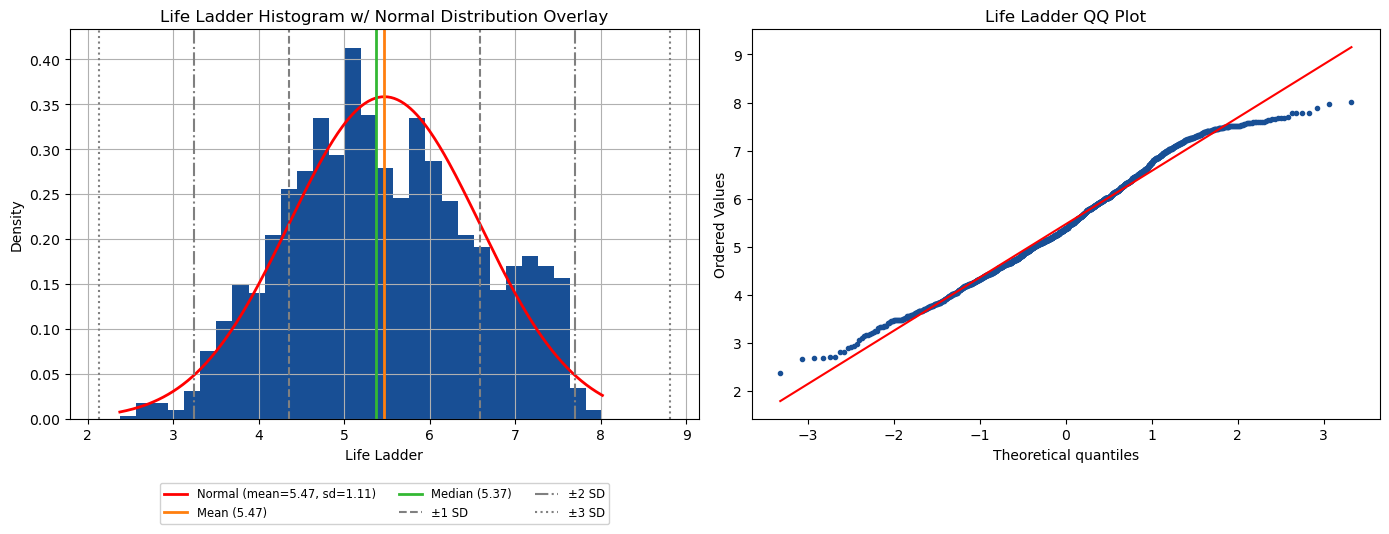

In [4]:
PLOTTING.continuous_distribution_plots(series=train_df[Q1_CONSTS.TARGET]);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Roughly symmetric with light tails (excess kurtosis -0.67): there is no long tail of extreme labels to pull the fit.
- No missing values and no IQR outliers: every train row has a usable label.

### Special Treatment

- None: no transform, clipping or imputation is needed on `Life Ladder`.

# Perceptions of Corruption

In [5]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['POC']['col']], target=train_df[Q1_CONSTS.TARGET])

,Perceptions of corruption
count,1473.0
missing,86
% missing,5.516
mean,0.748
std,0.187
min,0.035
25%,0.691
50%,0.804
75%,0.873
max,0.983


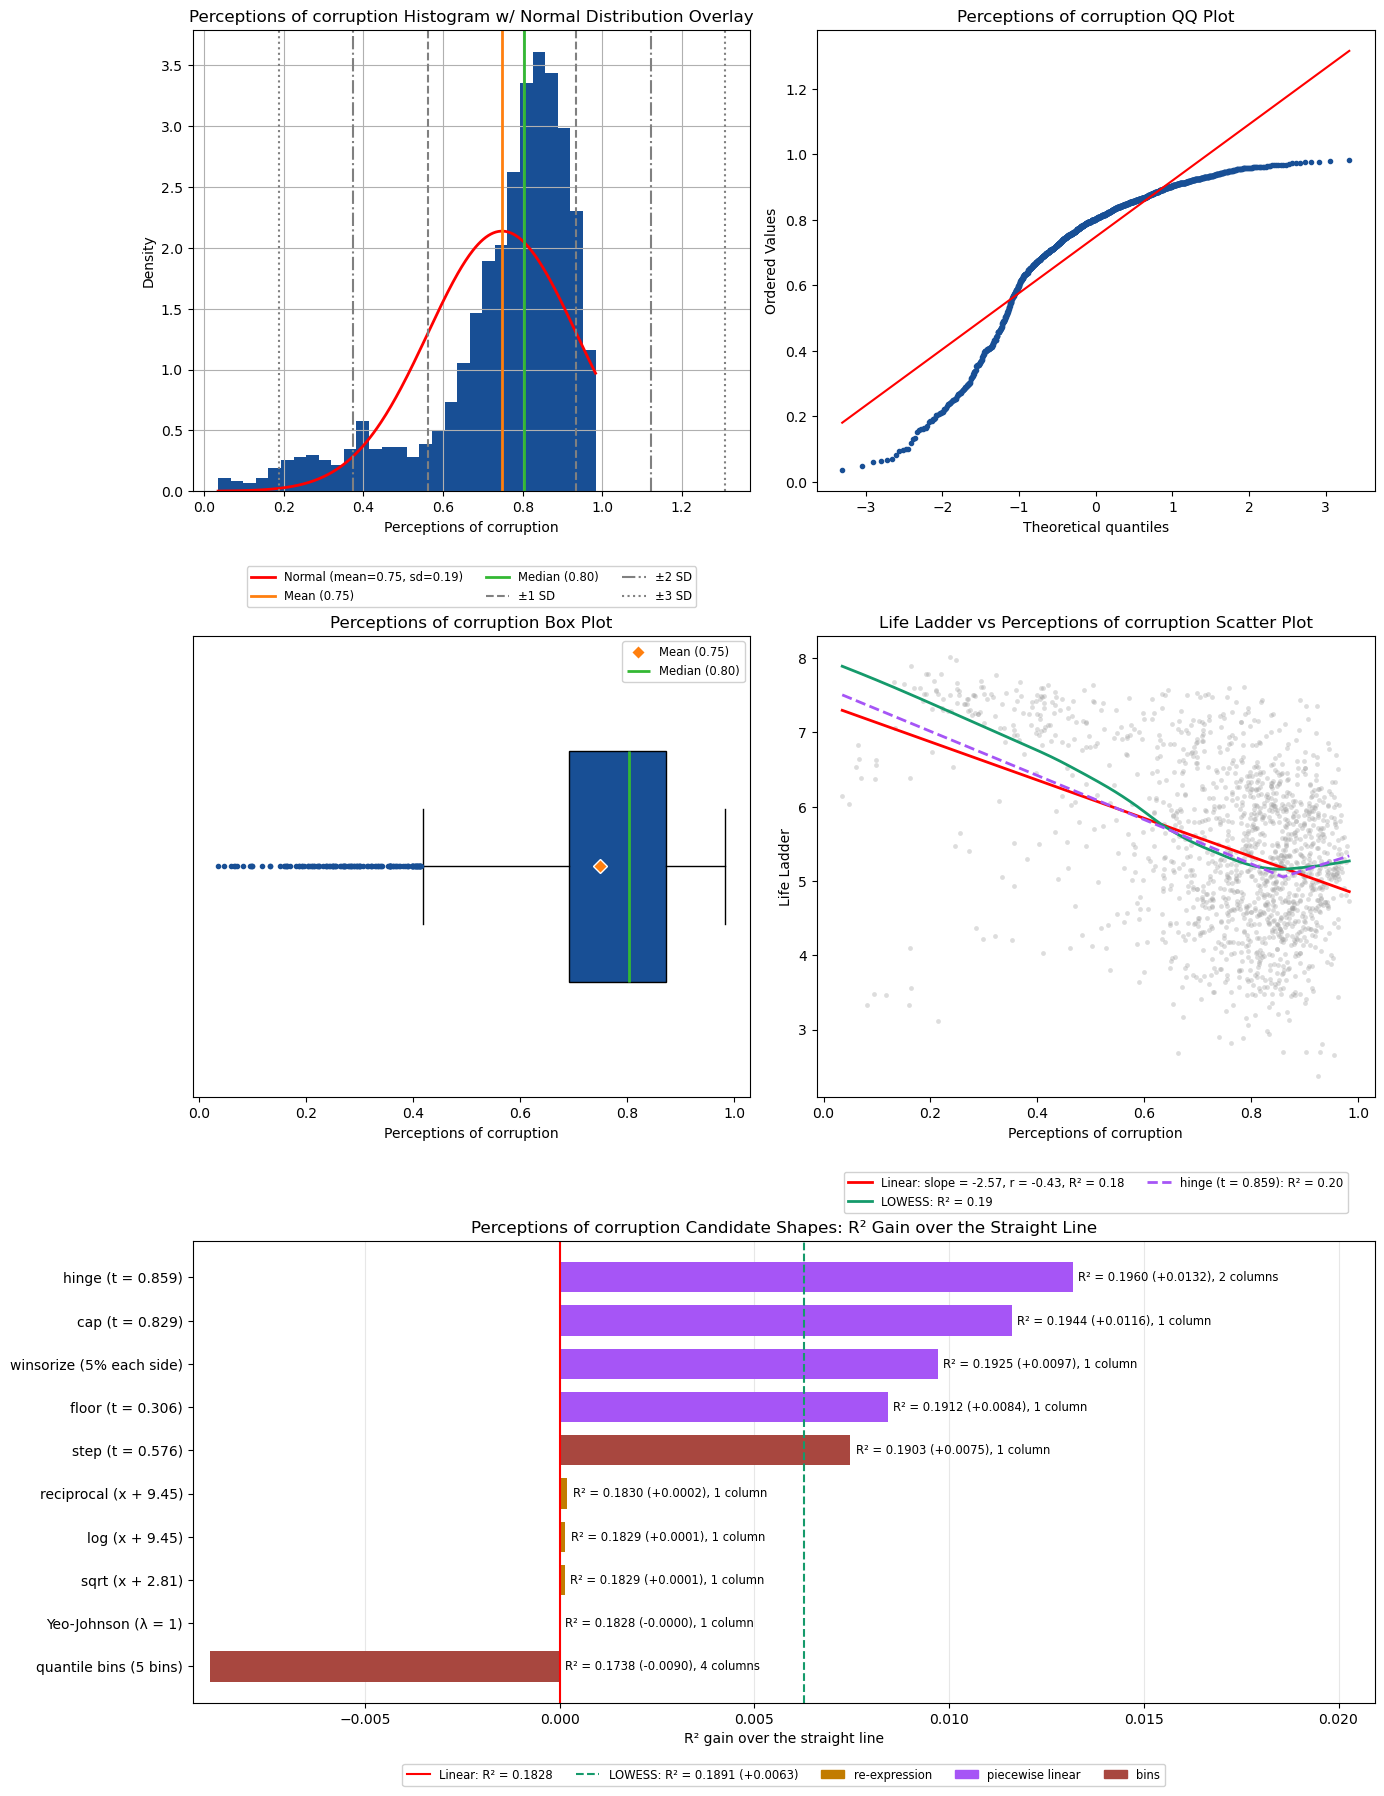

In [6]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['POC']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- The straight line already captures almost all of the shape: even LOWESS beats it by only 0.0063 in R², so no reshaping of this column can move its predictions much.
- The signal is in the low tail: above about 0.8 LOWESS is flat, so the column says little among the rows crowded at the top (median 0.804).
- The 130 low IQR outliers are on the trend: they are the rows with the highest `Life Ladder`, LOWESS keeps falling through them, and the straight line slightly under-predicts them.
- 86 rows are missing, and the left skew pulls the mean below the median, so the fill value matters more here.

### Special Treatment

- **Feature engineering:** keep the raw value and avoid every piecewise and bins shape: the best, the hinge at t = 0.859, gains only +0.0132. Avoid a low corruption flag (step at t = 0.576, +0.0075): LOWESS keeps falling on both sides of the cut.
- **Transformations:** avoid the whole re-expression family: log, sqrt, reciprocal and Yeo-Johnson all gain +0.0002 or less. Avoid winsorize (5% each side, +0.0097).
- **Outliers:** keep the 130 low outliers, do not clip or drop them: they sit on the falling part of LOWESS.
- **Imputation:** fill the 86 missing rows with the median (0.804), not the mean (0.748), which the low tail pulls down. A 0 / 1 missing flag is worth testing: the median puts all 86 rows on the flat part, where this column barely changes the prediction.

# Social Support

In [7]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['SS']['col']], target=train_df[Q1_CONSTS.TARGET])

,Social support
count,1549.0
missing,10
% missing,0.641
mean,0.813
std,0.119
min,0.29
25%,0.753
50%,0.835
75%,0.905
max,0.987


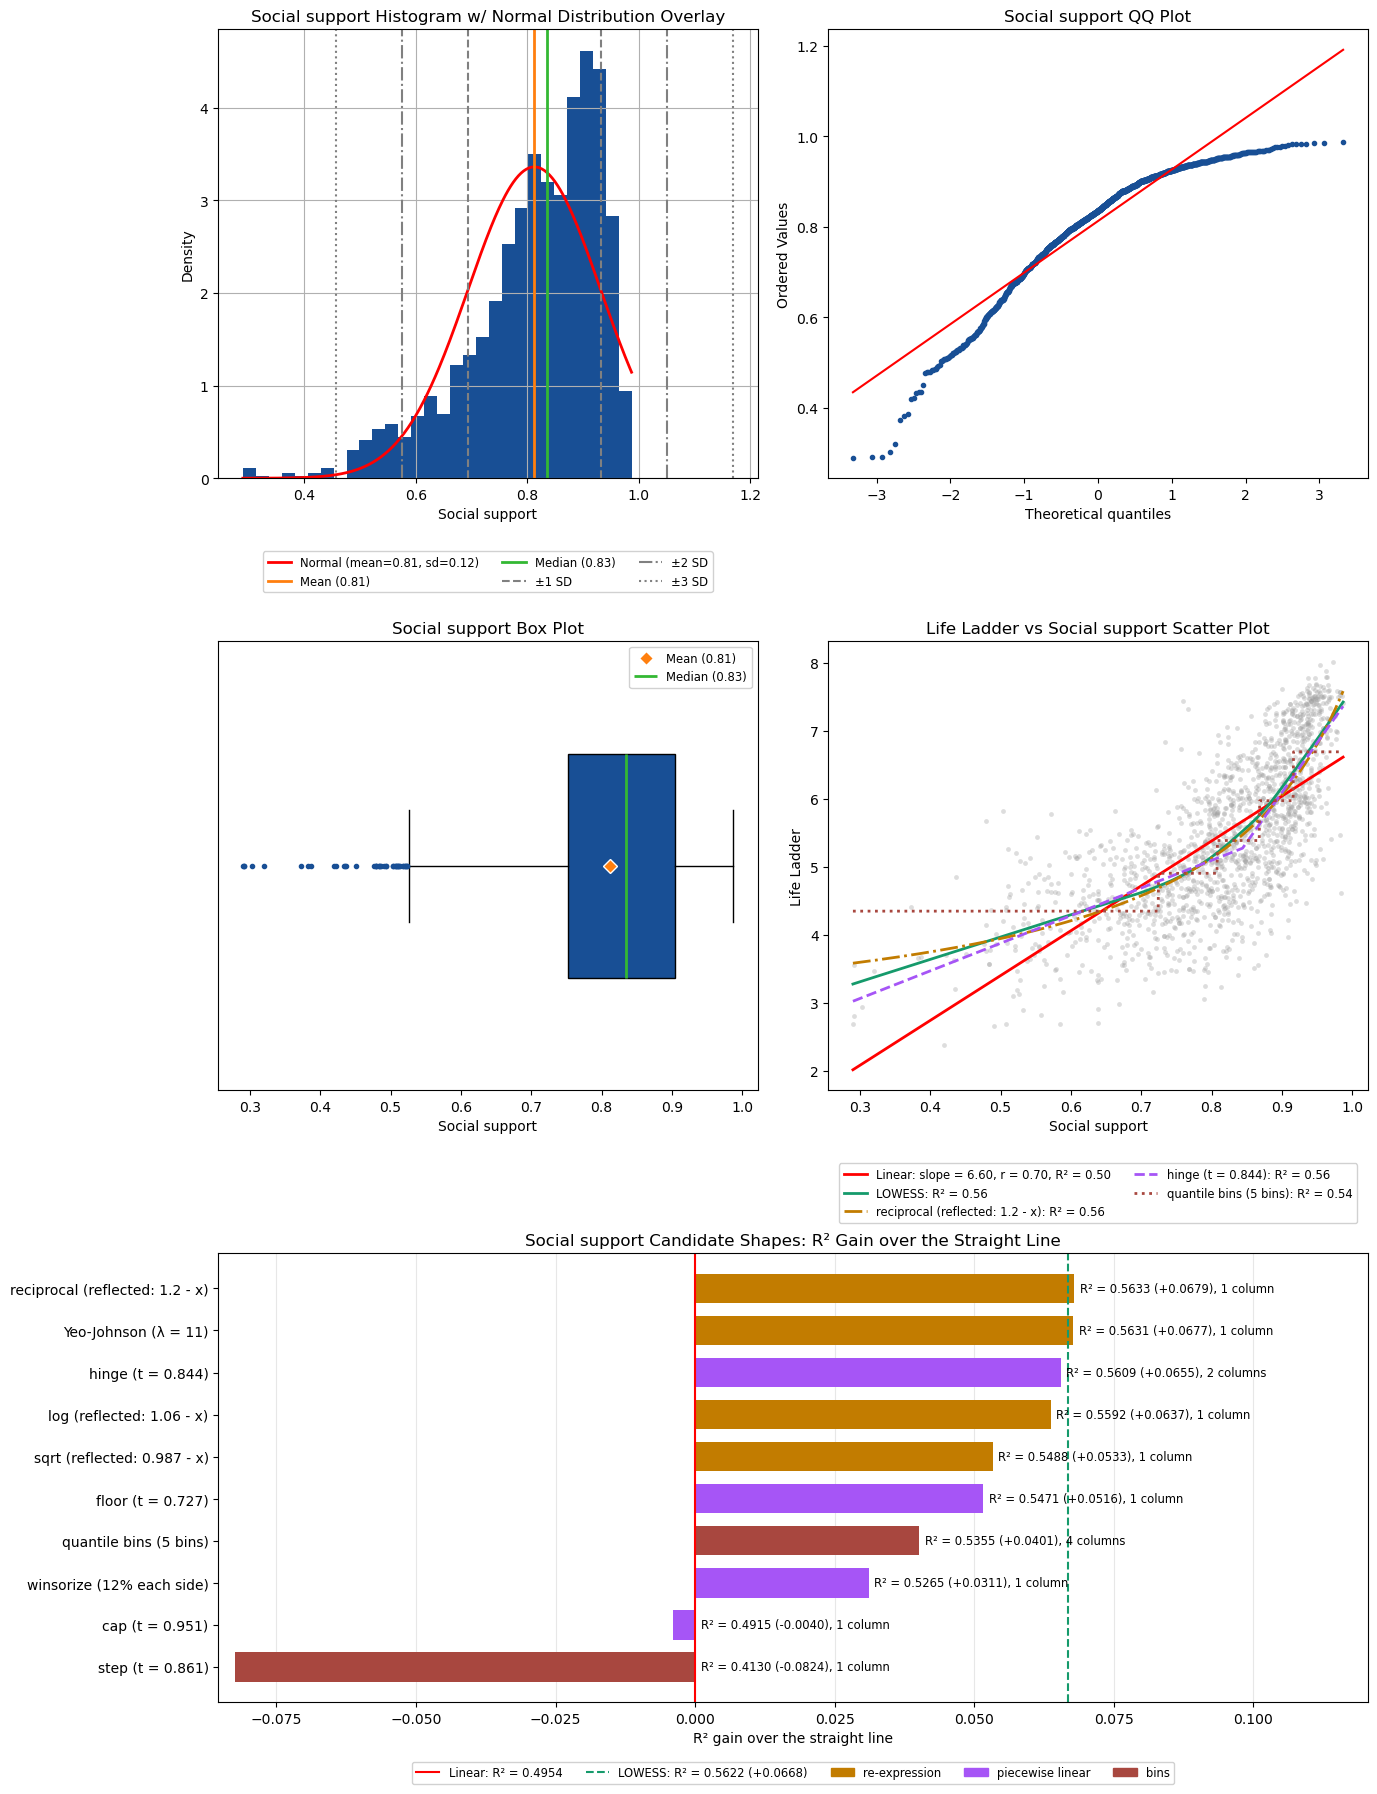

In [8]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['SS']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Shallow, then steep: the straight line under-predicts `Life Ladder` at both ends and over-predicts in the middle (about 0.65 to 0.9), which costs R² 0.50 against 0.56 for LOWESS.
- The bend is gradual: one column re-expressions that bend hardest at the top fit as well as the two column hinge (R² 0.5633 for the reflected reciprocal, 0.5609 for the hinge), so a second column is not needed.
- The 42 low IQR outliers follow the shallow part of LOWESS, so the misfit at the low end comes from the straight line, not from the outliers.

### Special Treatment

- **Feature engineering:** the hinge at t = 0.844 (+0.0655, 2 columns) is recommended. The floor at t = 0.727 (+0.0516) and quantile bins (+0.0401) also clear the bar, with less gain.
- **Feature engineering:** avoid the step at t = 0.861 (-0.0824) and the cap at t = 0.951 (-0.0040): both flatten the top, where `Life Ladder` rises fastest.
- **Transformations:** recommend a re-expression that is steep at the high end, the reciprocal of `1.2 - x` (+0.0679) or Yeo-Johnson at λ = 11 (+0.0677): one column, level with LOWESS (+0.0668). The reflected log and sqrt also clear the bar. Winsorize (12% each side, +0.0311) clears it too, but ranks last, and it clips the low tail that LOWESS runs through.
- **Outliers:** keep the 42 low outliers, do not drop them: LOWESS and the best shapes run through them.
- **Imputation:** fill the 10 missing rows with the median (0.835): the left skew (-1.138) pulls the mean down.

# Generosity

In [9]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['G']['col']], target=train_df[Q1_CONSTS.TARGET])

,Generosity
count,1488.0
missing,71
% missing,4.554
mean,0.0
std,0.163
min,-0.335
25%,-0.113
50%,-0.025
75%,0.091
max,0.698


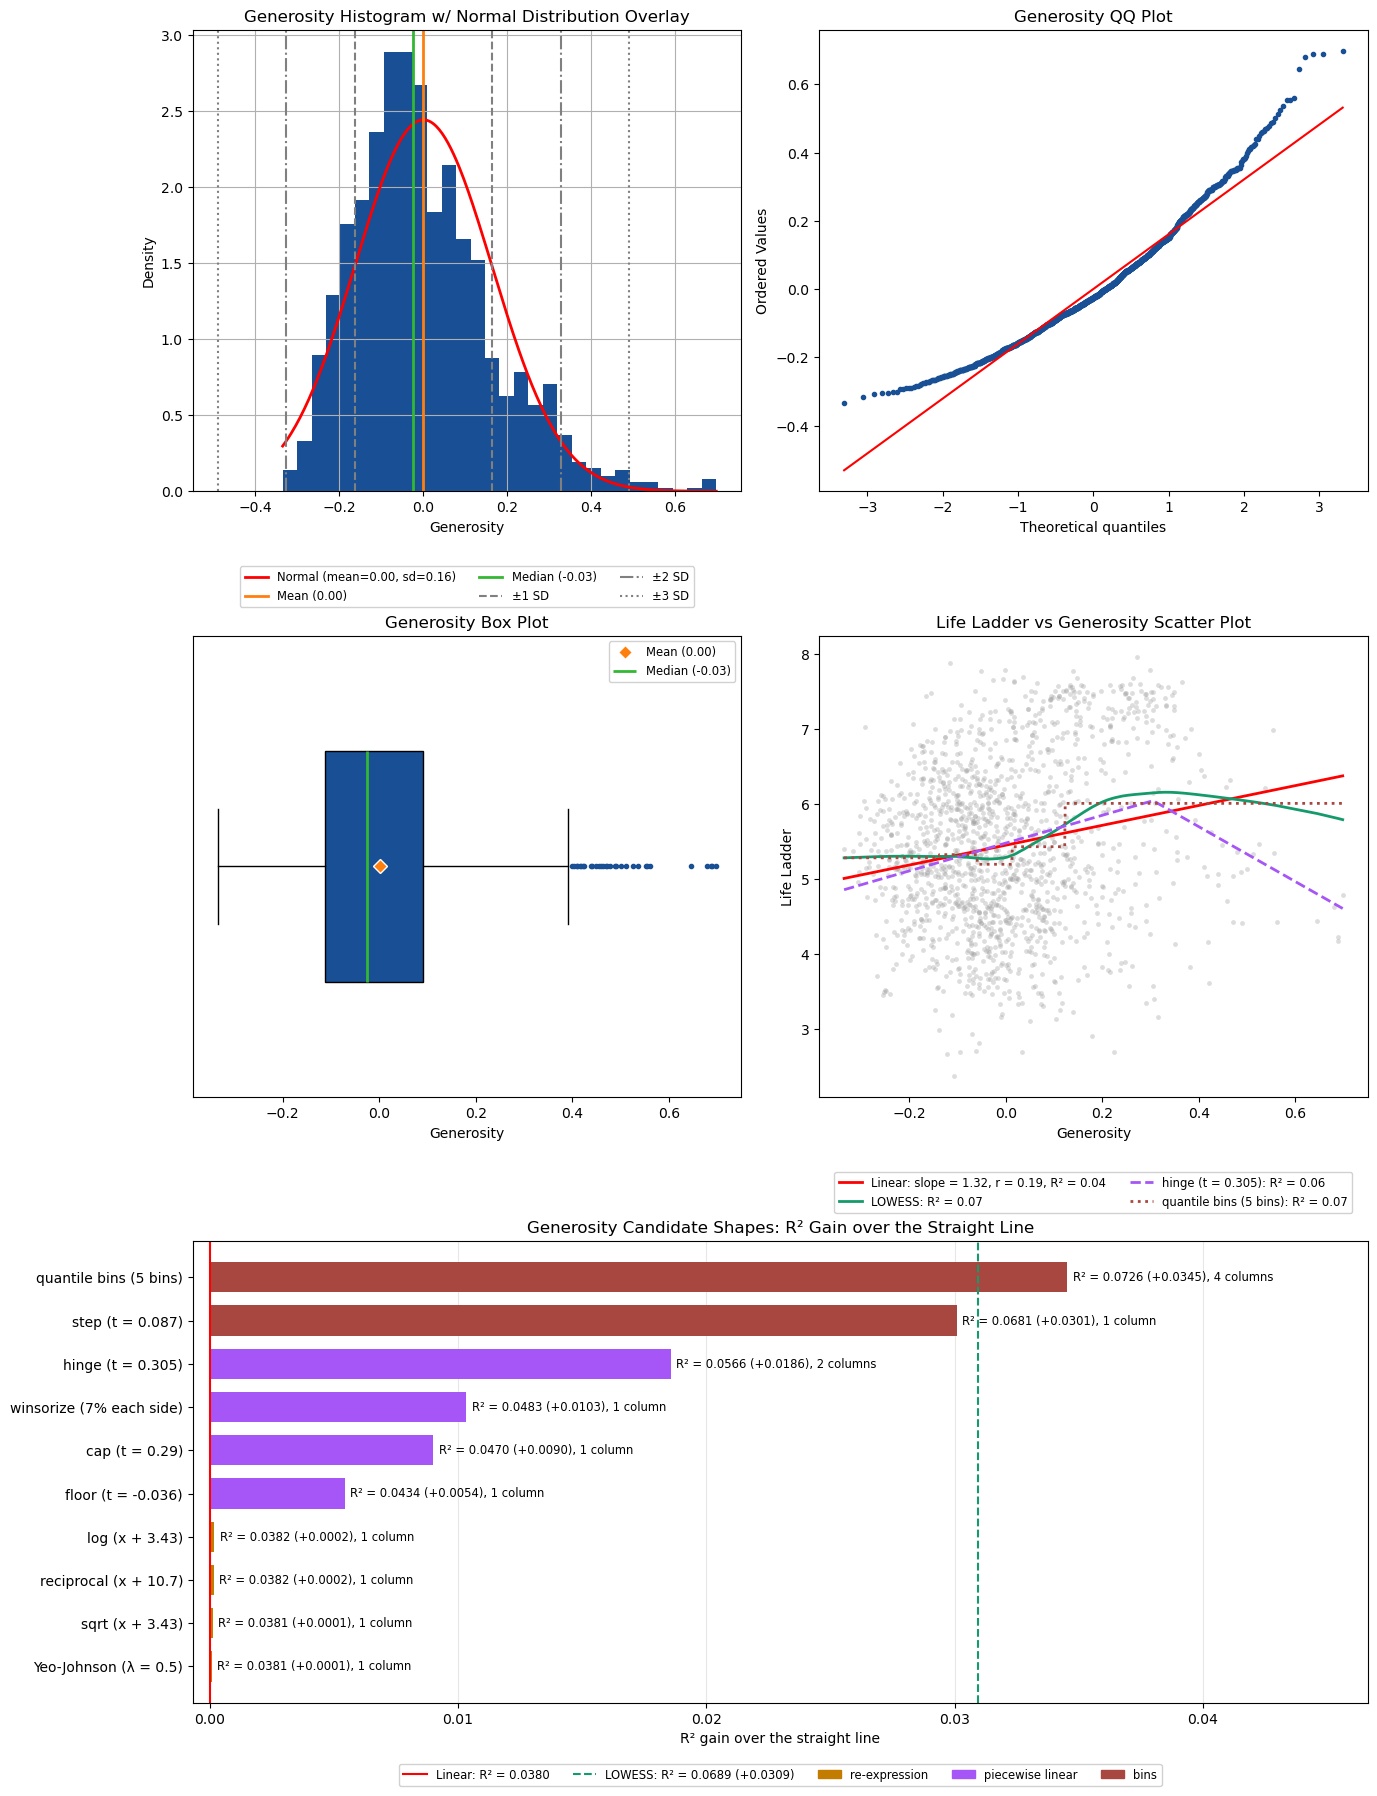

In [10]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['G']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Weak in any shape: even LOWESS explains only R² 0.07 of `Life Ladder`, so this column can move the predictions only a little.
- The signal is a level shift, not a slope: LOWESS is flat up to about 0.1, rises to a higher level, then drifts down. A single 0 / 1 flag reaches LOWESS (R² 0.0681 against 0.0689), while the straight line keeps rising where LOWESS does not.
- The 31 high IQR outliers sit off the straight line: past about 0.4 LOWESS drifts down while the line keeps rising, so the line over-predicts them.
- 71 rows are missing, so the fill value decides the flag for a sizable group of rows.

### Special Treatment

- **Dropping:** test the model without it: even LOWESS only reaches R² 0.07.
- **Feature engineering:** if kept, replace the raw value with a high generosity flag, 1 when x is at or above 0.087 (step at t = 0.087, +0.0301, 1 column). Quantile bins gain about the same (+0.0347) with 4 columns, so the flag is the better choice.
- **Feature engineering:** the hinge at t = 0.305 is worth testing, small gain (+0.0186). Avoid the cap at t = 0.29 (+0.0090) and the floor at t = -0.036 (+0.0054).
- **Transformations:** avoid the whole re-expression family: log, sqrt, reciprocal and Yeo-Johnson all gain +0.0002 or less. Avoid winsorize (7% each side, +0.0103).
- **Outliers:** do not clip the 31 high outliers as a separate step: the flag already gives them the same value as every row at or above 0.087, and winsorizing the raw value gains only +0.0103.
- **Imputation:** if kept, fill the 71 missing rows with the median (-0.025), which puts them all on the low side of the flag (0). A 0 / 1 missing flag is worth testing with this many rows.

# Healthy Life Expectancy at Birth

In [11]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['HLEAB']['col']], target=train_df[Q1_CONSTS.TARGET])

,Healthy life expectancy at birth
count,1522.0
missing,37
% missing,2.373
mean,63.332
std,7.478
min,32.3
25%,58.34
50%,65.18
75%,68.535
max,77.1


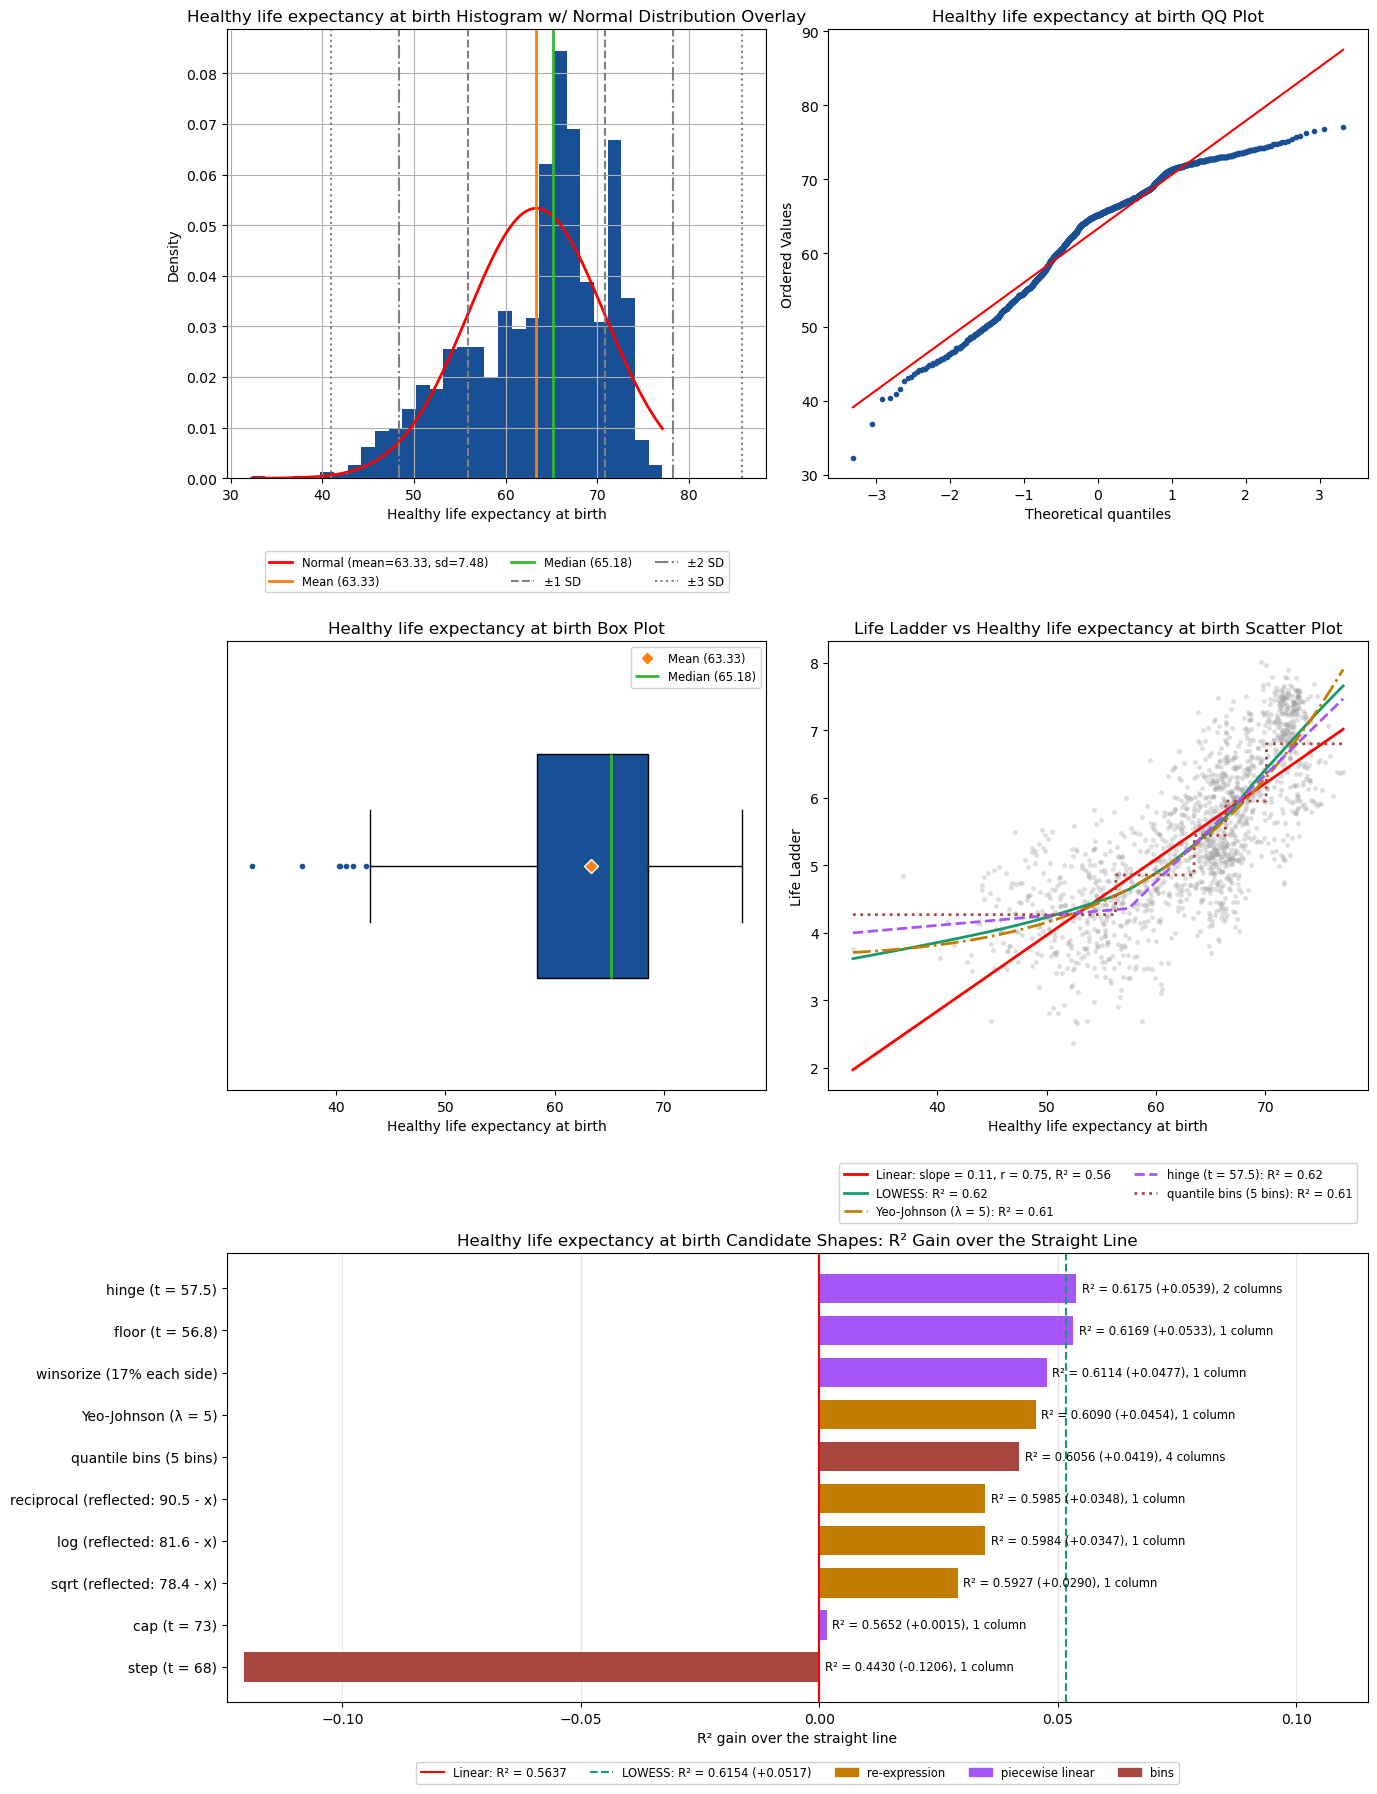

In [12]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['HLEAB']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Shallow, then steep: below about 55 LOWESS rises only slowly, while the straight line keeps its slope and predicts far too low at the low end, which costs R² 0.56 against 0.62 for LOWESS.
- The bend is a corner: below about 57 the attribute barely changes the prediction, so a one column floor fits as well as the two column hinge (R² 0.6169 against 0.6175).
- The 7 low IQR outliers sit on the flat part of LOWESS. They are off the straight line only because the line extends its slope into them.
- Large scale (std 7.478): unscaled, a penalty or gradient step treats this column very differently from a column near unit scale.

### Special Treatment

- **Feature engineering:** recommend a floor at t = 56.8 (`max(x, 56.8)`, +0.0533, 1 column) or the hinge at t = 57.5 (+0.0539, 2 columns): the same gain, both above LOWESS (+0.0517). Quantile bins (+0.0420) also clear the bar, with 4 columns.
- **Feature engineering:** avoid the step at t = 68 (-0.1206) and the cap at t = 73 (+0.0015): a step drops the slope above the bend, and a cap flattens the top, where `Life Ladder` rises fastest.
- **Transformations:** Yeo-Johnson at λ = 5 (+0.0454) and winsorize (17% each side, +0.0477) are recommended one column alternatives. The reflected reciprocal, log and sqrt also clear the bar (+0.0290 to +0.0348), but the piecewise family fits this corner better.
- **Scaling:** standardize: std 7.478.
- **Outliers:** keep the 7 low outliers, do not drop them: they sit on the flat part of LOWESS, and the floor at 56.8 already gives them the same value as the rest of that part.
- **Imputation:** fill the 37 missing rows with the median (65.18): the left skew (-0.723) pulls the mean down.

# Negative Affect

In [13]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['NA']['col']], target=train_df[Q1_CONSTS.TARGET])

,Negative affect
count,1545.0
missing,14
% missing,0.898
mean,0.268
std,0.084
min,0.083
25%,0.206
50%,0.258
75%,0.319
max,0.705


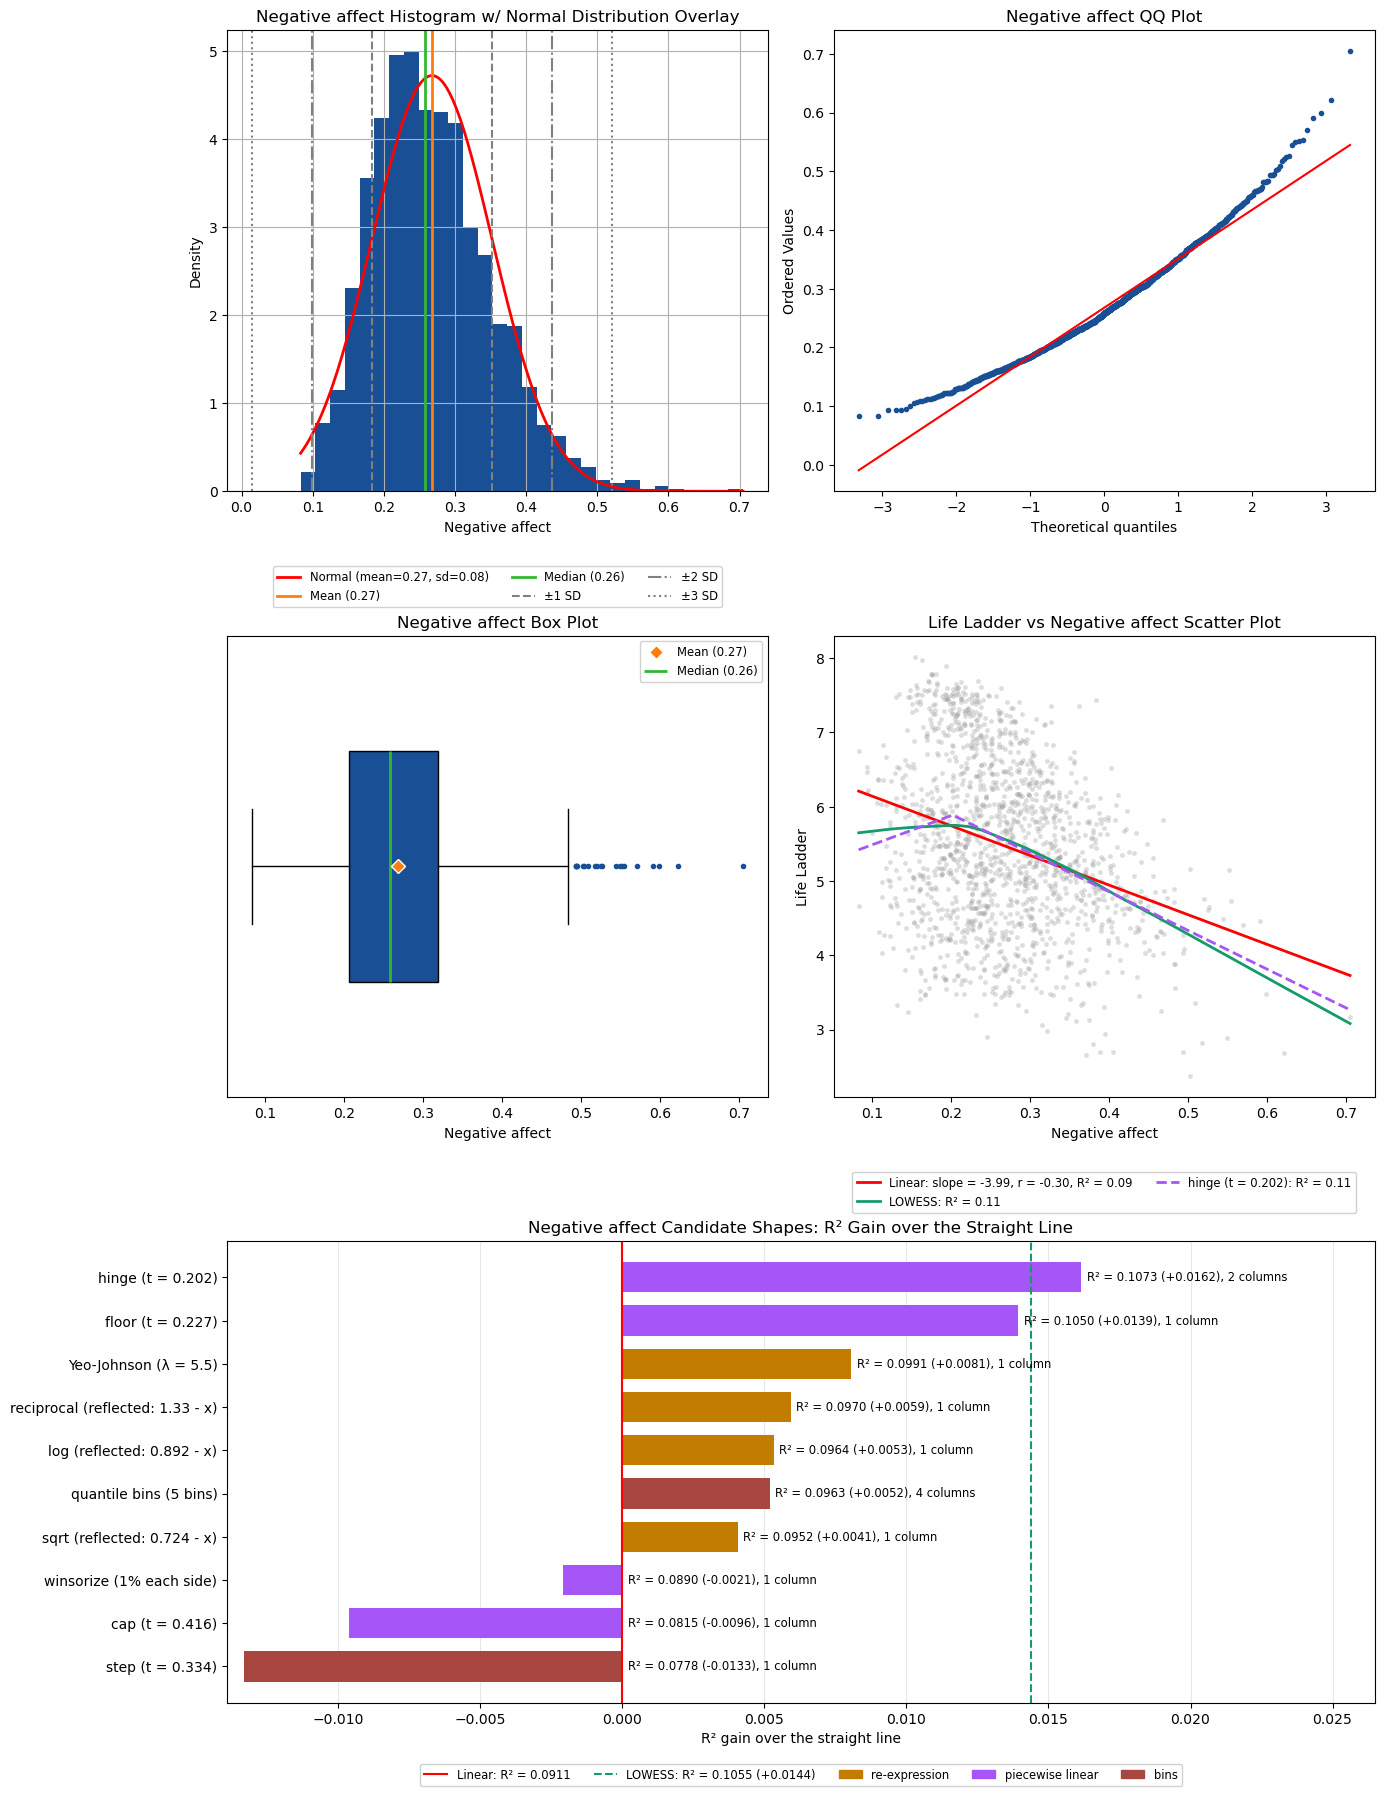

In [14]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['NA']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Weak in any shape: linear R² 0.09, and even LOWESS only reaches 0.11, so this column can move the predictions only a little.
- Flat, then falling: LOWESS is level up to about 0.2, then falls to the max. The straight line over-predicts at both ends, and the hinge at 0.202 follows LOWESS.
- The 20 high IQR outliers sit on the falling part of LOWESS, so they follow the trend, and shapes that pull them in (cap, winsorize) lose R².
- The right skew points to log or sqrt, but every re-expression gains 0.01 or less, so the skew is not a reason to transform.

### Special Treatment

- **Dropping:** test the model without it: no shape lifts R² above 0.11.
- **Feature engineering:** if kept, the hinge at t = 0.202 is worth testing, small gain (+0.0162). Avoid every other piecewise and bins shape (+0.0139 or less), including a high negative affect flag (step), which loses R².
- **Transformations:** avoid the whole re-expression family: the best, Yeo-Johnson at λ = 5.5, gains only +0.0081. Avoid winsorize (1% each side, -0.0021).
- **Outliers:** keep the 20 high outliers, do not clip or drop them: they sit on the falling part of LOWESS.
- **Imputation:** fill the 14 missing rows with the median (0.258): the right skew (0.696) pulls the mean up.

# Freedom to Make Life Choices

In [15]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['FTMLC']['col']], target=train_df[Q1_CONSTS.TARGET])

,Freedom to make life choices
count,1537.0
missing,22
% missing,1.411
mean,0.742
std,0.142
min,0.26
25%,0.646
50%,0.763
75%,0.855
max,0.985


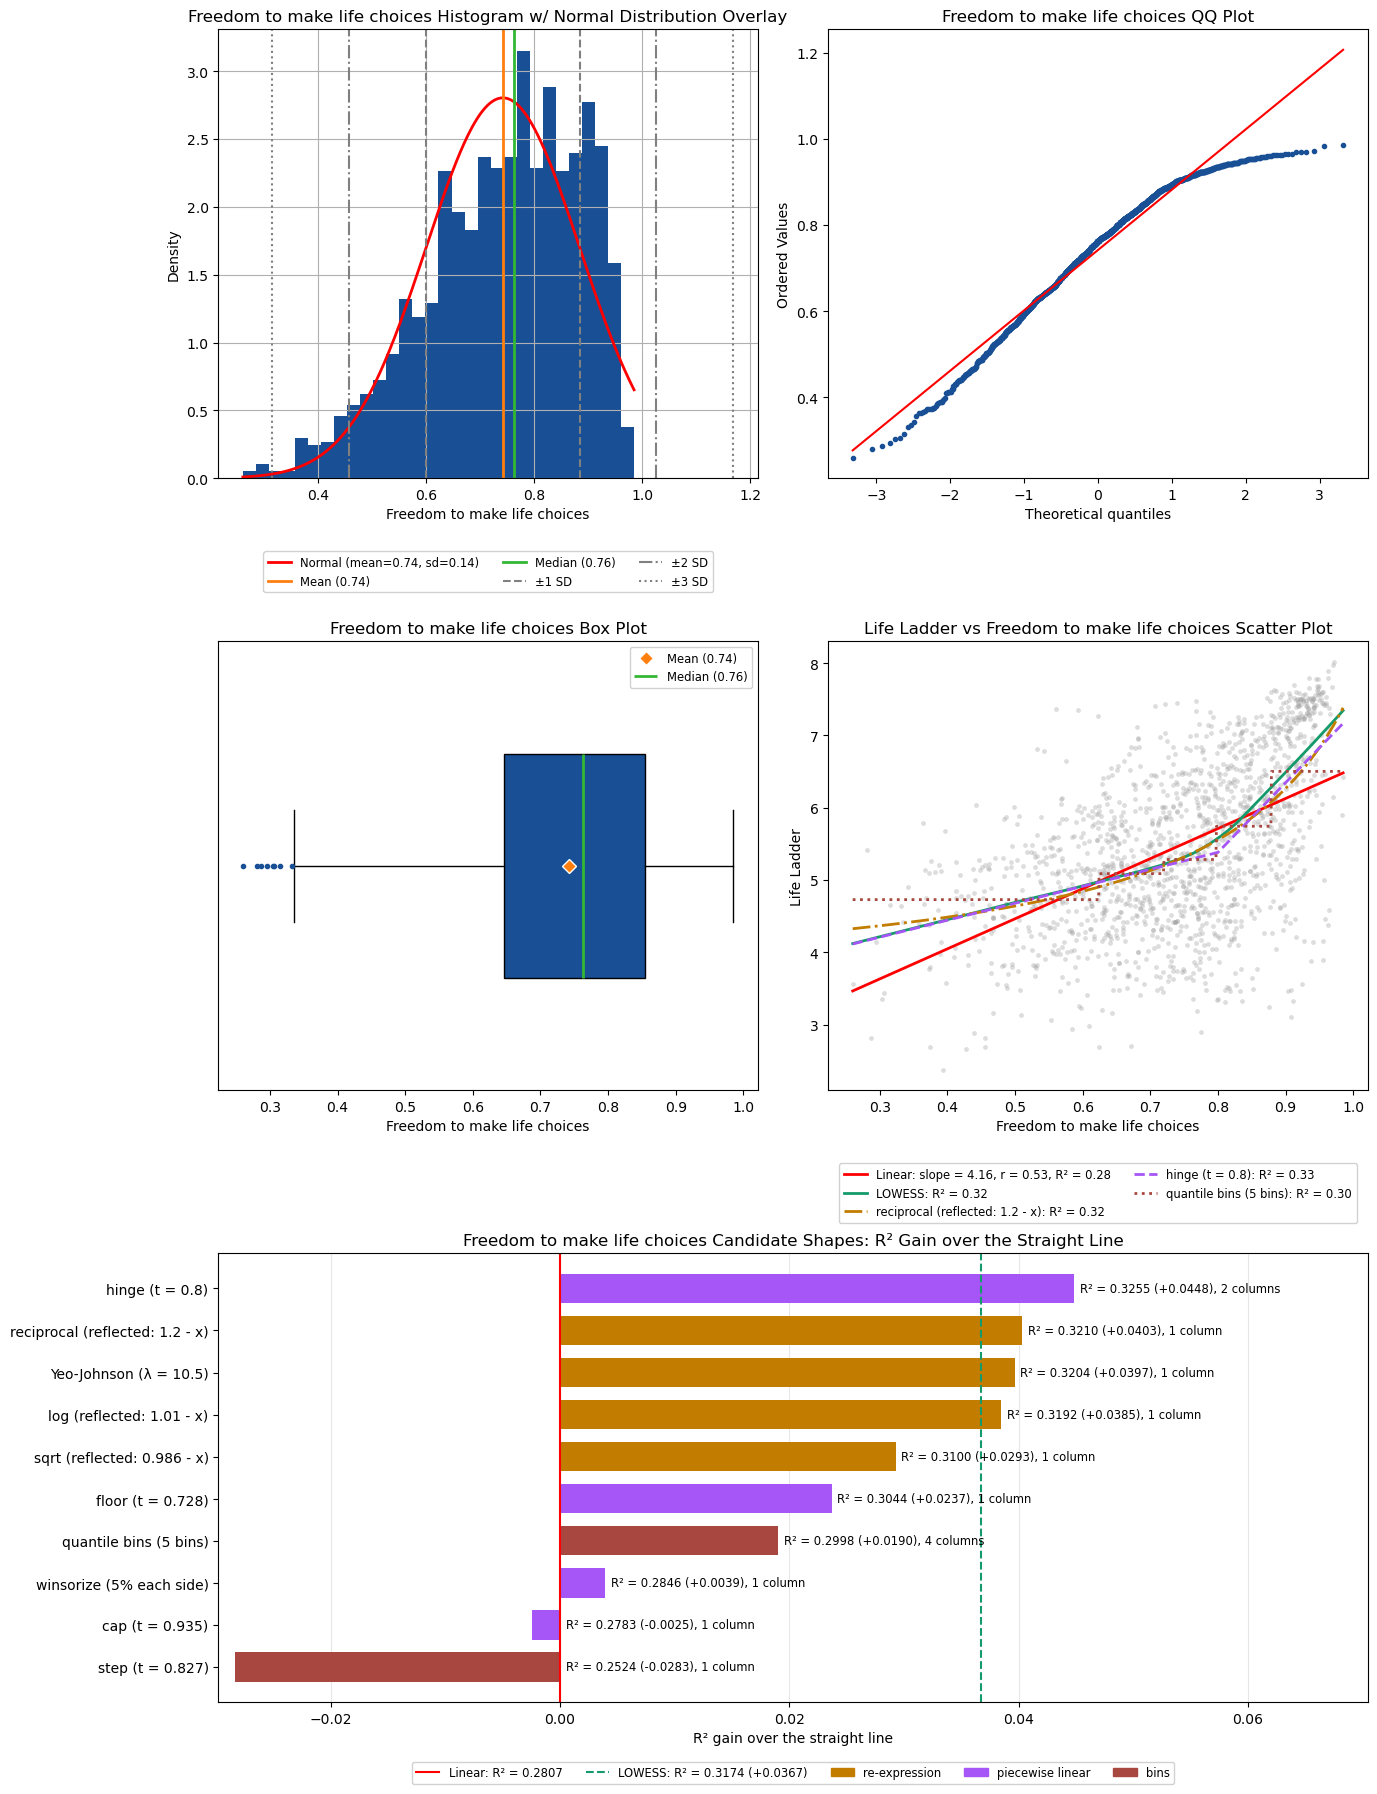

In [16]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['FTMLC']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Shallow, then steep: LOWESS bends upward near 0.8. The straight line under-predicts `Life Ladder` at both ends and over-predicts just below the bend, which costs R² 0.28 against 0.32 for LOWESS.
- The low side still rises, so it carries signal: the floor, which makes everything below 0.728 flat, gains about half of what the hinge gains (+0.0237 against +0.0448). Keep a slope below the bend.
- The bend is gradual enough that one column re-expressions that bend hardest at the top come within 0.01 of the hinge (R² 0.3210 for the reflected reciprocal, 0.3255 for the hinge).
- The 8 low IQR outliers follow the straight low part of LOWESS, so they are on the trend.

### Special Treatment

- **Feature engineering:** recommend the hinge at t = 0.8, alongside the raw value (+0.0448, 2 columns, the best shape, above LOWESS at +0.0367). The floor at t = 0.728 (+0.0237) and quantile bins (+0.0191) are worth testing, small gain. Avoid the step at t = 0.827 (-0.0283) and the cap at t = 0.935 (-0.0025).
- **Transformations:** recommend a re-expression that is steep at the high end as the one column alternative to the hinge: the reciprocal of `1.2 - x` (+0.0403), Yeo-Johnson at λ = 10.5 (+0.0397) or the log of `1.01 - x` (+0.0385). The reflected sqrt (`0.986 - x`, +0.0293) also clears the bar. Avoid winsorize (5% each side, +0.0039).
- **Outliers:** keep the 8 low outliers, do not clip them: LOWESS rises through the low end at a steady rate.
- **Imputation:** fill the 22 missing rows with the median (0.763): the left skew (-0.606) pulls the mean down.

# Positive Affect

In [17]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['PA']['col']], target=train_df[Q1_CONSTS.TARGET])

,Positive affect
count,1542.0
missing,17
% missing,1.09
mean,0.709
std,0.108
min,0.322
25%,0.623
50%,0.721
75%,0.798
max,0.944


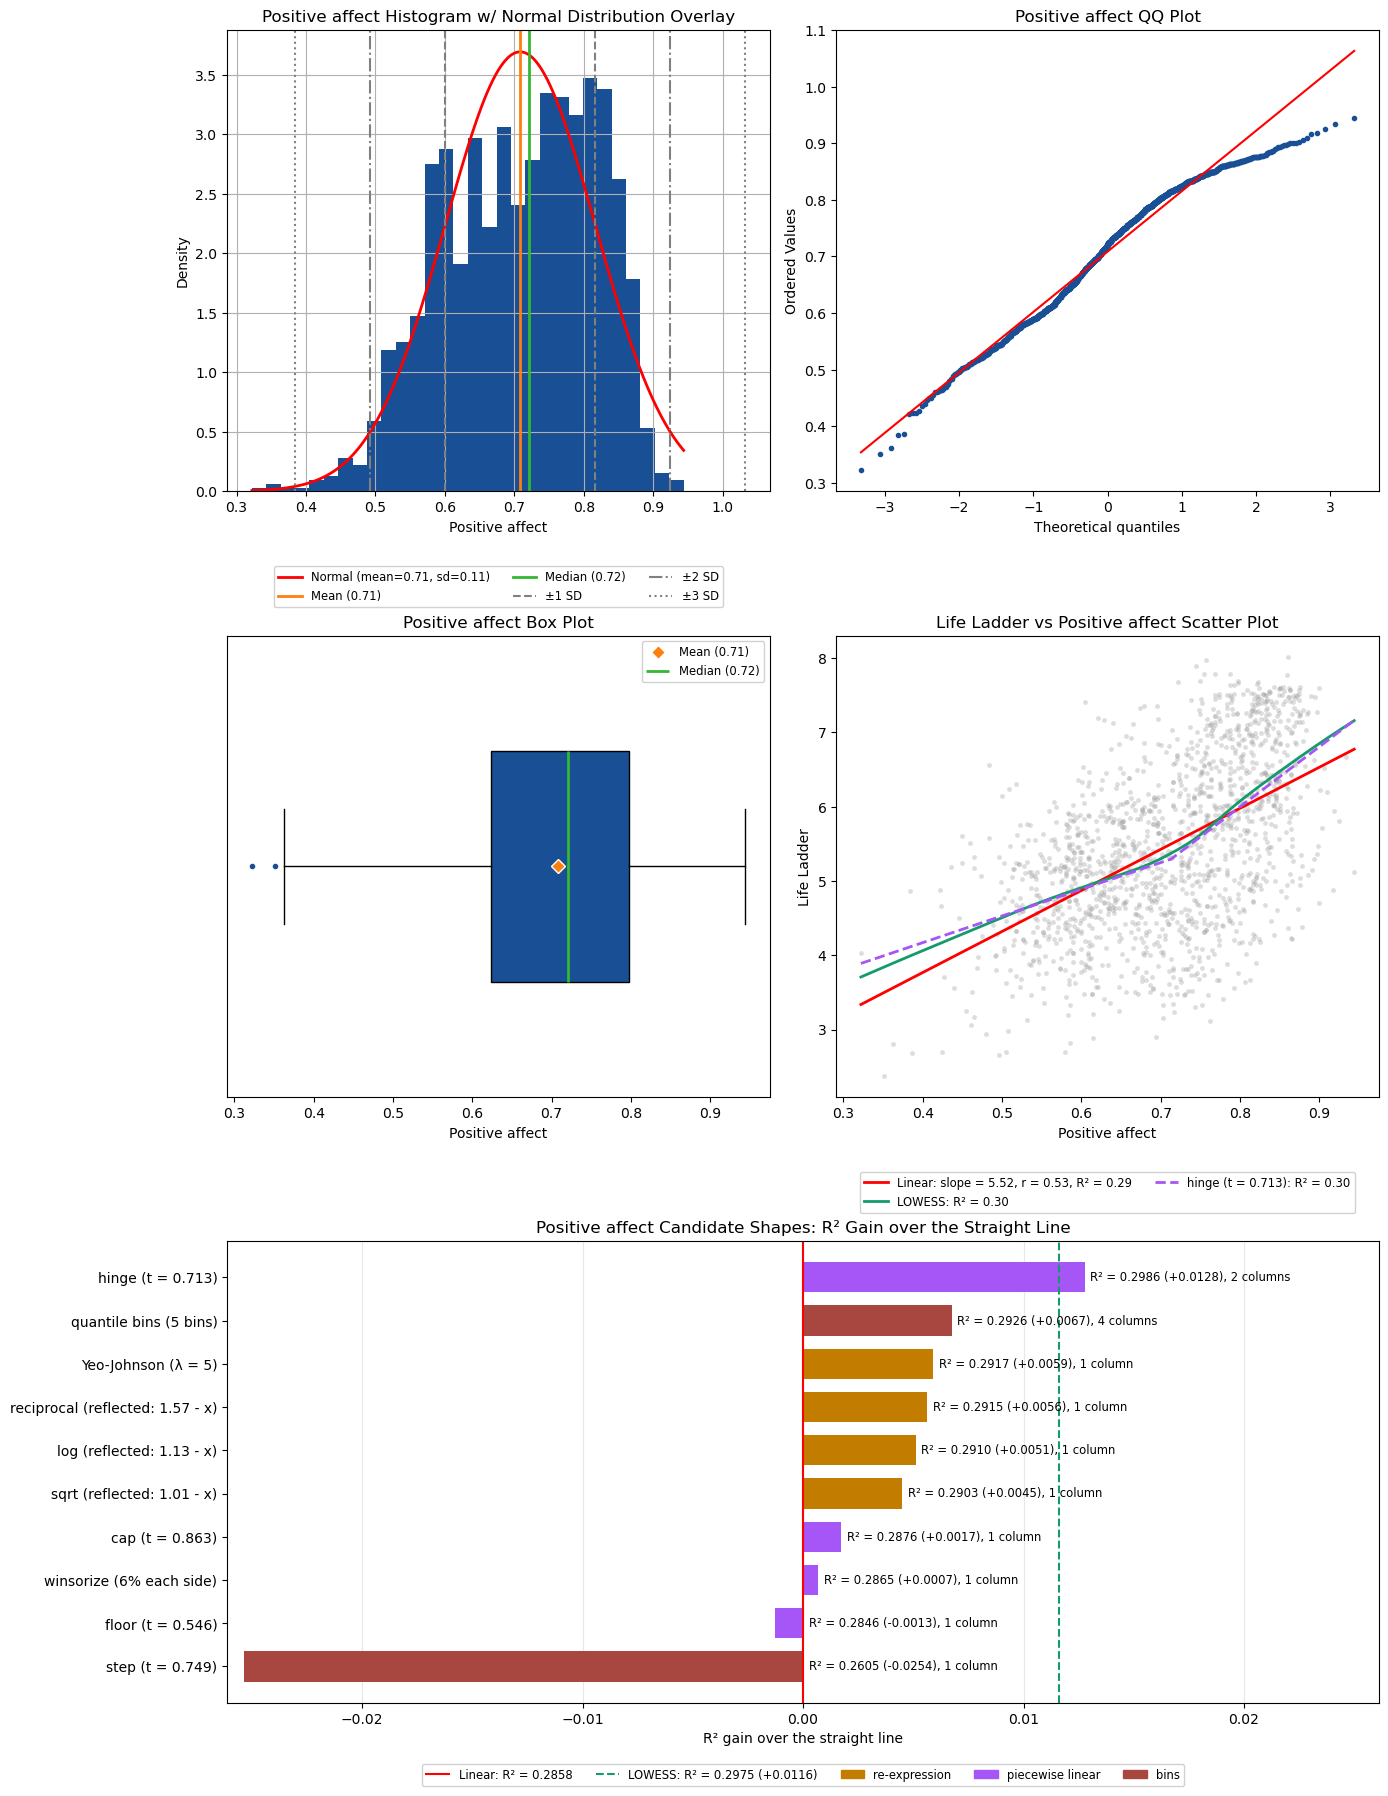

In [18]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['PA']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Already close to a straight line: even LOWESS beats it by only 0.0116 in R², so no shape has room to change the predictions.
- Cutting the column into levels throws away a slope that holds across the whole range: the 0 / 1 step loses R² (-0.0254).

### Special Treatment

- **Feature engineering:** keep the raw value and avoid every piecewise and bins shape: the best, the hinge at t = 0.713, gains only +0.0128.
- **Transformations:** avoid the whole re-expression family: the best, Yeo-Johnson at λ = 5, gains only +0.0059. Avoid winsorize (6% each side, +0.0007).
- **Imputation:** fill the 17 missing rows with the mean (0.709) or the median (0.721): the distribution is roughly symmetric, so the two are close.

# Log GDP per Capita

In [19]:
STATISTICS.continuous_statistics_df(series=train_df[Q1_CONSTS.COLUMNS['LGDP']['col']], target=train_df[Q1_CONSTS.TARGET])

,Log GDP per capita
count,1533.0
missing,26
% missing,1.668
mean,9.363
std,1.16
min,6.635
25%,8.46
50%,9.456
75%,10.332
max,11.648


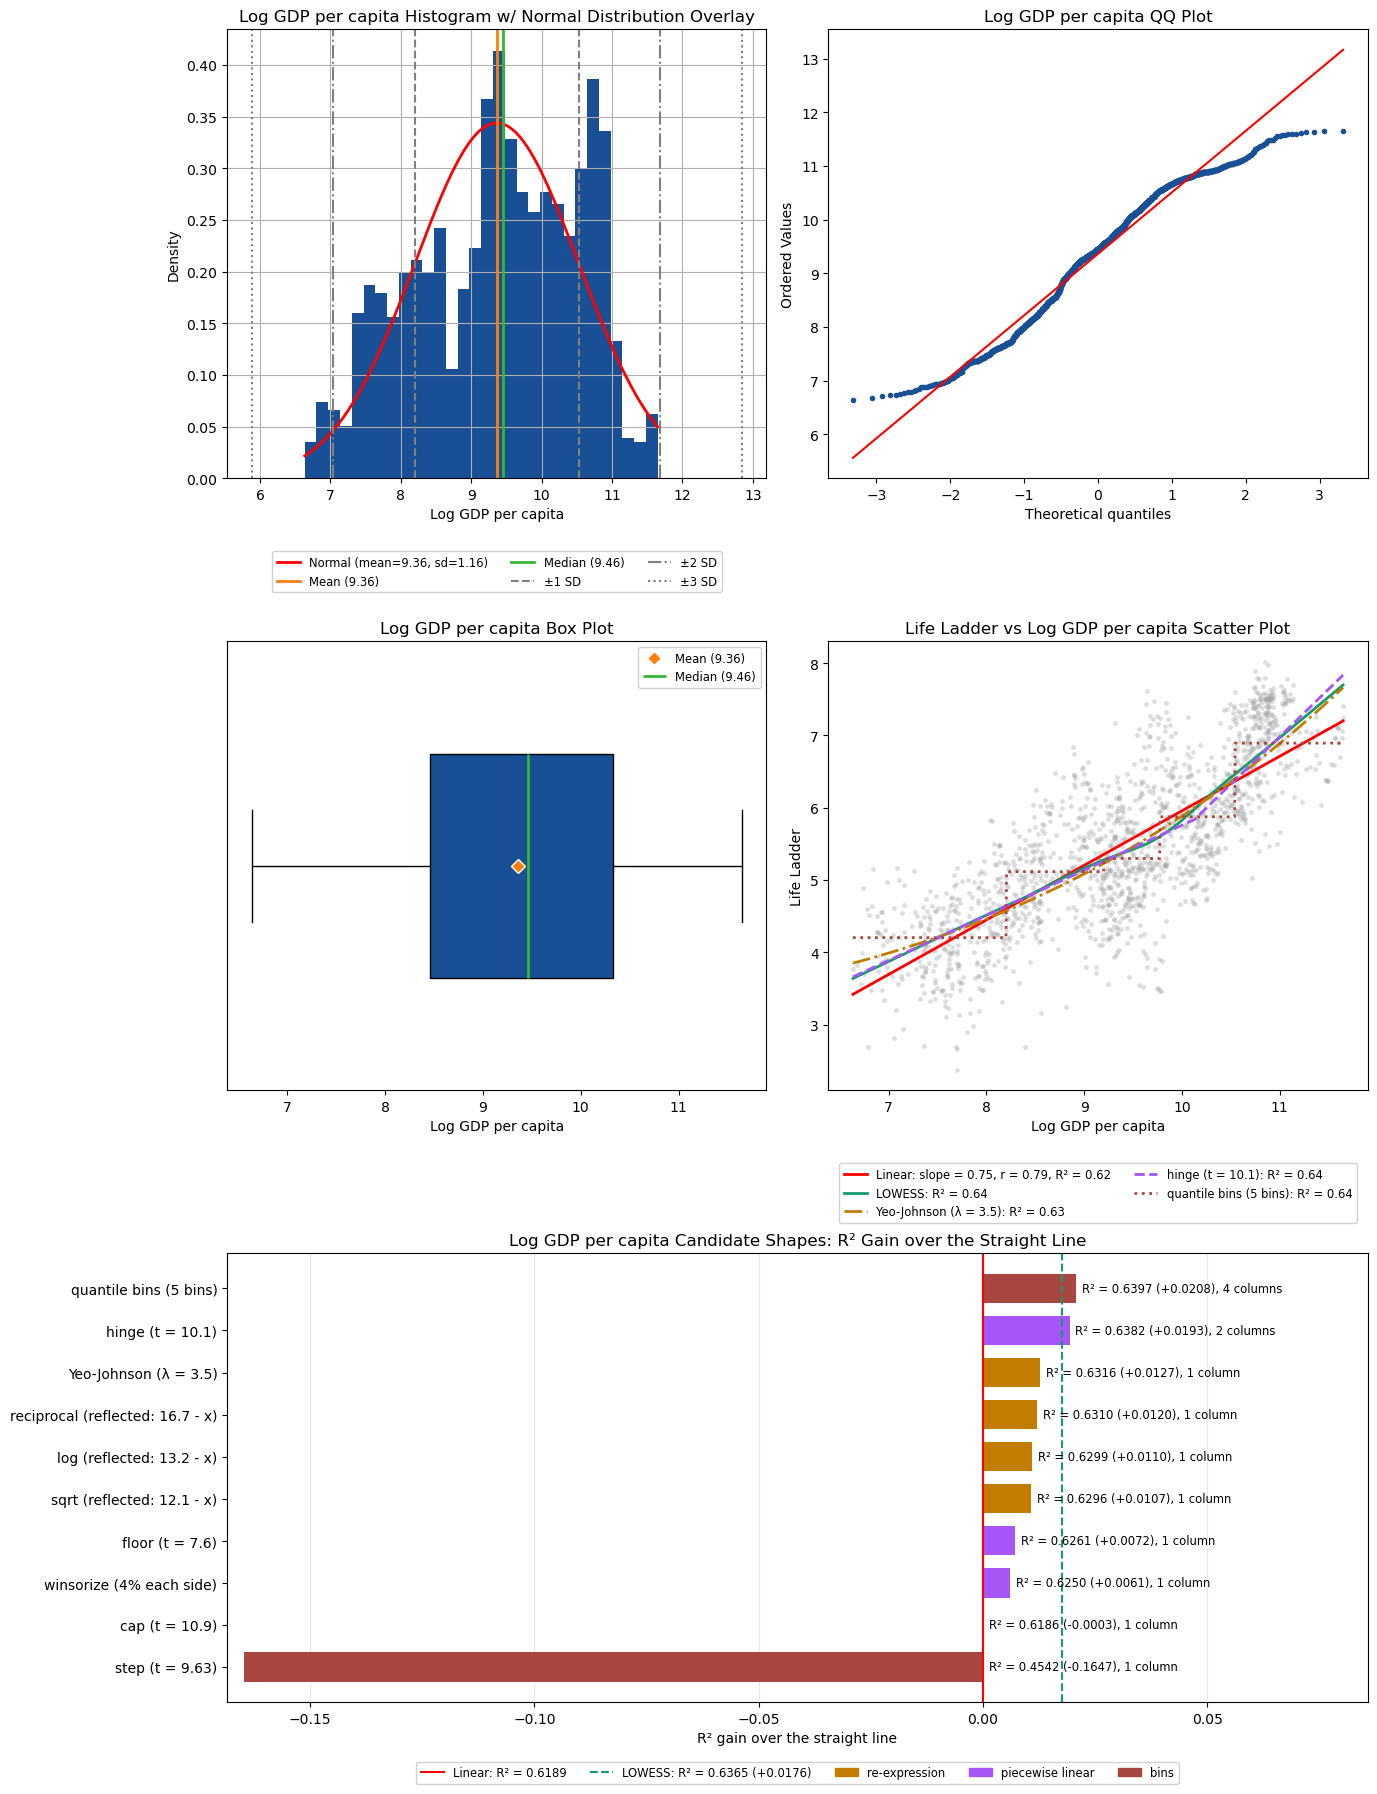

In [20]:
PLOTTING.continuous_single_feature_plots(df=train_df, feature=Q1_CONSTS.COLUMNS['LGDP']['col'], target=Q1_CONSTS.TARGET);

## Notes / Observations

### Noticeable Traits / Key Attributes

- Already close to a straight line: LOWESS beats it by only 0.0176 in R², so a shape can add little.
- The slope steepens above about 10: the straight line under-predicts the top end, and the hinge at 10.1 and quantile bins follow that bend.
- Roughly symmetric with no IQR outliers, so there is nothing to clip and the fill value matters little.

### Special Treatment

- **Feature engineering:** the hinge at t = 10.1 (+0.0193, 2 columns) and quantile bins (+0.0208, 4 columns) are worth testing, small gain. Prefer the hinge: the same gain with 2 columns instead of 4. Avoid the step, the cap and the floor (+0.0072 or less): the step alone loses R² (-0.1647).
- **Transformations:** avoid the whole re-expression family: the best, Yeo-Johnson at λ = 3.5, gains only +0.0127. Avoid winsorize (4% each side, +0.0061).
- **Scaling:** standardize: std 1.16.
- **Imputation:** fill the 26 missing rows with the mean (9.363) or the median (9.456): the distribution is roughly symmetric, so the two are close.